<a href="https://colab.research.google.com/github/AlfredaDhaifullah04/PCVK_Ganjil_2026/blob/main/PCVK_M9_W9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Modul 9 - Morfologi Citra
Notebook ini memuat implementasi praktikum Modul 9: Erosi, Dilasi, Opening, Closing, Top-hat, Bottom-hat, Skeleton, dan Thickening.

**Penting:** Pastikan Anda menyesuaikan path gambar (`/content/drive/MyDrive/PCVK/Images/...`) dengan direktori Google Drive Anda.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1 & 2. Persiapan: Mount Google Drive dan Import Library


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import cv2
import numpy as np
from matplotlib import pyplot as plt
from skimage import io, filters, color, morphology
from skimage.util import img_as_float


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. Dilasi Tanpa Library (Cross 3x3)


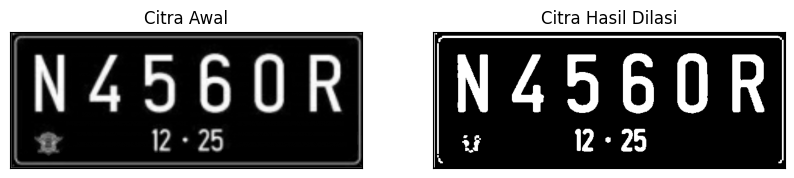

In [ ]:
# Dilasi tanpa library
def dilasi_citra(F, w):
    # size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

# Catatan: Sesuaikan path file gambar Anda
img_d = cv2.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /plat_nomor.png', 0)
if img_d is not None:
    ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
    w = 3 # Diubah ke 3 sesuai perintah cross 3x3, meski di PDF ditulis 5 di bawah
    imgD = dilasi_citra(thresh, w)

    plt.figure(figsize=(10,5))
    plt.subplot(121), plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(imgD, cmap='gray')
    plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
    plt.show()
else:
    print("Gambar tidak ditemukan. Cek path Google Drive Anda.")


## 4. Dilasi Dengan Library OpenCV (Cross 3x3)


Kernel: [[1 1 1]
 [1 1 1]
 [1 1 1]]


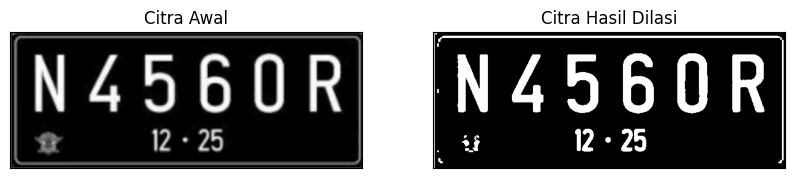

In [ ]:
img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /plat_nomor.png', 0)
if img is not None:
    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    kernel = np.ones((3,3), np.uint8)
    dilasi = cv2.dilate(thresh, kernel, iterations=1)

    print("Kernel:", kernel)
    plt.figure(figsize=(10,5))
    plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(dilasi, cmap='gray'), plt.title('Citra Hasil Dilasi')
    plt.xticks([]), plt.yticks([])
    plt.show()


## 5. Erosi Tanpa Library (Square 5x5)


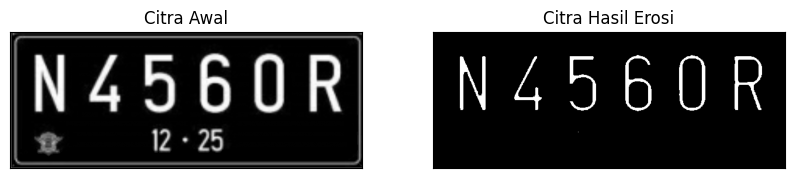

In [ ]:
# Erosi Tanpa Library
def erosi_citra(F, k):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant : i + constant + 1, j - constant : j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

img_e = cv2.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /plat_nomor.png', 0)
if img_e is not None:
    ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
    k = 5
    imgE = erosi_citra(thresh1, k)

    plt.figure(figsize=(10,5))
    plt.subplot(121), plt.imshow(img_e, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(imgE, cmap='gray')
    plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
    plt.show()


## 6. Erosi Dengan Library OpenCV (Square 5x5)


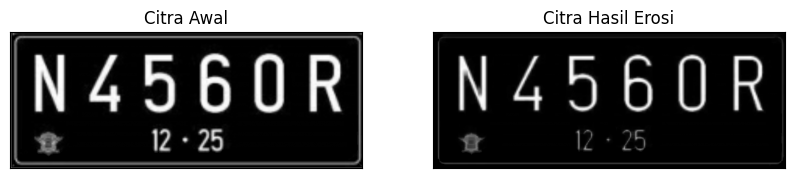

In [ ]:
# EROSI LIBRARY
img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /plat_nomor.png', 0)
if img is not None:
    kernel = np.ones((5,5), np.uint8)
    erosion = cv2.erode(img, kernel, iterations=1)

    plt.figure(figsize=(10,5))
    plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(erosion, cmap='gray'), plt.title('Citra Hasil Erosi')
    plt.xticks([]), plt.yticks([])
    plt.show()


## 7. Opening Tanpa dan Dengan Library


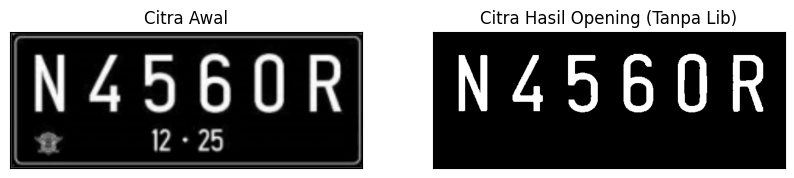

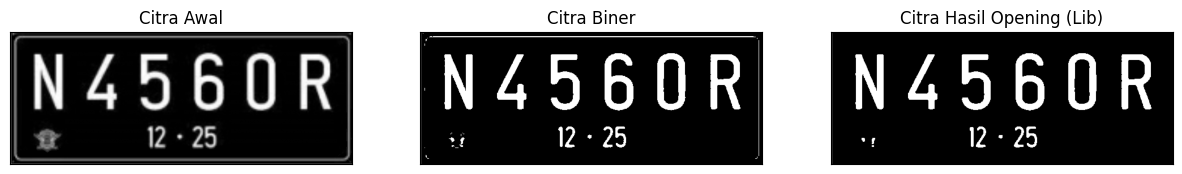

In [ ]:
# Operasi Opening Menggunakan tanpa Library Morphology (Kombinasi Erosi & Dilasi)
img_o = cv2.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /plat_nomor.png', 0)
if img_o is not None:
    ret0, thresh0 = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
    k = 7
    # Opening: Erosi dulu, lalu Dilasi
    imgO = dilasi_citra(erosi_citra(thresh0, k), k)

    plt.figure(figsize=(10,5))
    plt.subplot(121), plt.imshow(img_o, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(imgO, cmap='gray')
    plt.title('Citra Hasil Opening (Tanpa Lib)'), plt.xticks([]), plt.yticks([])
    plt.show()

# Dengan Menggunakan Library Morphology OpenCV
    kernel = np.ones((3,3), np.uint8)
    openn = cv2.morphologyEx(thresh0, cv2.MORPH_OPEN, kernel)

    plt.figure(figsize=(15,5))
    plt.subplot(131), plt.imshow(img_o, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(thresh0, cmap='gray')
    plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
    plt.subplot(133), plt.imshow(openn, cmap='gray')
    plt.title('Citra Hasil Opening (Lib)'), plt.xticks([]), plt.yticks([])
    plt.show()


## 8. Closing Tanpa dan Dengan Library


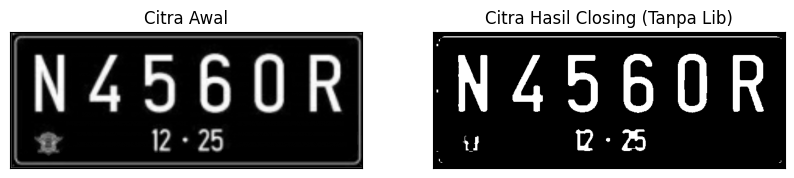

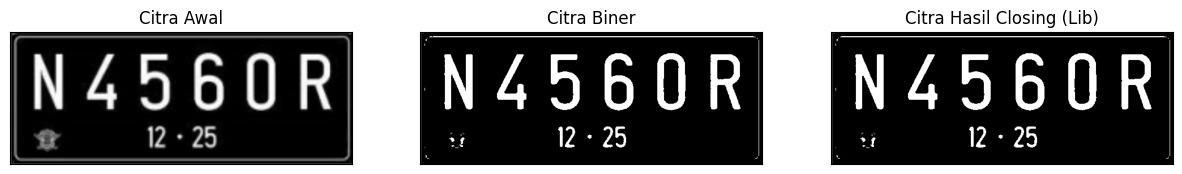

In [ ]:
# Operasi closing tanpa library morphology (Kombinasi Dilasi & Erosi)
img_c = cv2.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /plat_nomor.png', 0)
if img_c is not None:
    retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
    k = 7
    # Closing: Dilasi dulu, lalu Erosi
    imgC = erosi_citra(dilasi_citra(threshc, k), k)

    plt.figure(figsize=(10,5))
    plt.subplot(121), plt.imshow(img_c, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(imgC, cmap='gray')
    plt.title('Citra Hasil Closing (Tanpa Lib)'), plt.xticks([]), plt.yticks([])
    plt.show()

# Dengan Menggunakan Library Morphology OpenCV
    kernel = np.ones((3,3), np.uint8)
    closs = cv2.morphologyEx(threshc, cv2.MORPH_CLOSE, kernel)

    plt.figure(figsize=(15,5))
    plt.subplot(131), plt.imshow(img_c, cmap='gray')
    plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(threshc, cmap='gray')
    plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
    plt.subplot(133), plt.imshow(closs, cmap='gray')
    plt.title('Citra Hasil Closing (Lib)'), plt.xticks([]), plt.yticks([])
    plt.show()


## 9. Dilasi SED Cross 3x3 dan 5x5


SED = Cross 3x3


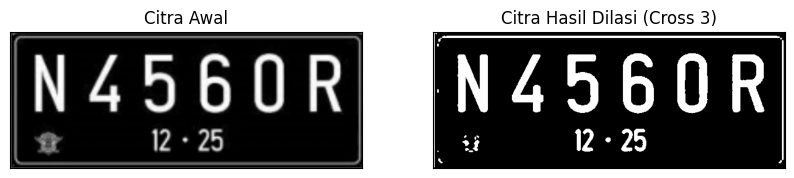

SED = Cross 5x5


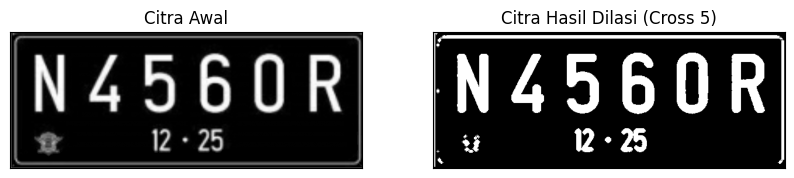

In [ ]:
# Dilasi Cross 3x3
def dilasi_citra_cross(F, SED):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    w = SED.shape[0]
    constant1 = (w - 1) // 2

    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            # Element-wise masking
            product = np.where(SED == 1, temp, 0)
            imgD[i, j] = np.max(product)
    return imgD

img_d = cv2.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /plat_nomor.png', 0)
if img_d is not None:
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

    print('SED = Cross 3x3')
    SED_3 = np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]], dtype=np.uint8)
    imgD_3 = dilasi_citra_cross(thresh, SED_3)

    plt.figure(figsize=(10,5))
    plt.subplot(121), plt.imshow(img_d, cmap='gray'), plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(imgD_3, cmap='gray'), plt.title('Citra Hasil Dilasi (Cross 3)')
    plt.xticks([]), plt.yticks([])
    plt.show()

    print('SED = Cross 5x5')
    SED_5 = np.array([[0, 0, 1, 0, 0],
                      [0, 0, 1, 0, 0],
                      [1, 1, 1, 1, 1],
                      [0, 0, 1, 0, 0],
                      [0, 0, 1, 0, 0]], dtype=np.uint8)
    imgD_5 = dilasi_citra_cross(thresh, SED_5)

    plt.figure(figsize=(10,5))
    plt.subplot(121), plt.imshow(img_d, cmap='gray'), plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(imgD_5, cmap='gray'), plt.title('Citra Hasil Dilasi (Cross 5)')
    plt.xticks([]), plt.yticks([])
    plt.show()


## 10. Dilasi Circular 3x3 dan 5x5


SED = Circle 3x3


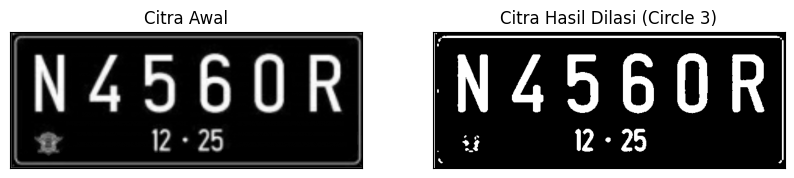

SED = Circle 5x5


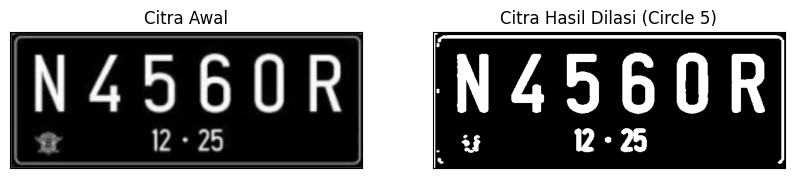

In [ ]:
# Dilasi Circular SED menggunakan cv2.getStructuringElement
img_d = cv2.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /plat_nomor.png', 0)
if img_d is not None:
    ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

    print('SED = Circle 3x3')
    SED_circ_3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    imgD_circ_3 = cv2.dilate(thresh, SED_circ_3, iterations=1)

    plt.figure(figsize=(10,5))
    plt.subplot(121), plt.imshow(img_d, cmap='gray'), plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(imgD_circ_3, cmap='gray'), plt.title('Citra Hasil Dilasi (Circle 3)')
    plt.xticks([]), plt.yticks([])
    plt.show()

    print('SED = Circle 5x5')
    SED_circ_5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    imgD_circ_5 = cv2.dilate(thresh, SED_circ_5, iterations=1)

    plt.figure(figsize=(10,5))
    plt.subplot(121), plt.imshow(img_d, cmap='gray'), plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(imgD_circ_5, cmap='gray'), plt.title('Citra Hasil Dilasi (Circle 5)')
    plt.xticks([]), plt.yticks([])
    plt.show()


## 11. Erosi Rectangle 3x5 dan 5x7


SE = Rectangle 3x5 (width=3, height=5)


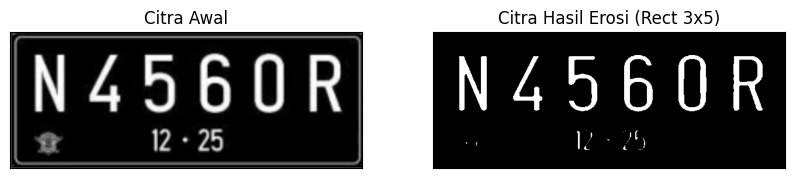

SE = Rectangle 5x7 (width=5, height=7)


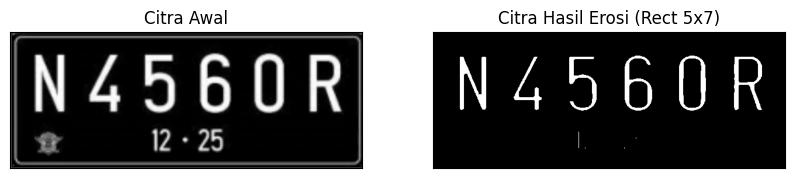

In [ ]:
img_e = cv2.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /plat_nomor.png', 0)
if img_e is not None:
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

    print('SE = Rectangle 3x5 (width=3, height=5)')
    SE_rect_1 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 5))
    imgE_rect_1 = cv2.erode(thresh1, SE_rect_1, iterations=1)

    plt.figure(figsize=(10,5))
    plt.subplot(121), plt.imshow(img_e, cmap='gray'), plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(imgE_rect_1, cmap='gray'), plt.title('Citra Hasil Erosi (Rect 3x5)')
    plt.xticks([]), plt.yticks([])
    plt.show()

    print('SE = Rectangle 5x7 (width=5, height=7)')
    SE_rect_2 = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 7))
    imgE_rect_2 = cv2.erode(thresh1, SE_rect_2, iterations=1)

    plt.figure(figsize=(10,5))
    plt.subplot(121), plt.imshow(img_e, cmap='gray'), plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(imgE_rect_2, cmap='gray'), plt.title('Citra Hasil Erosi (Rect 5x7)')
    plt.xticks([]), plt.yticks([])
    plt.show()


## 12. Erosi Line Vertikal 3 dan 5


SE = Line Vertikal 3


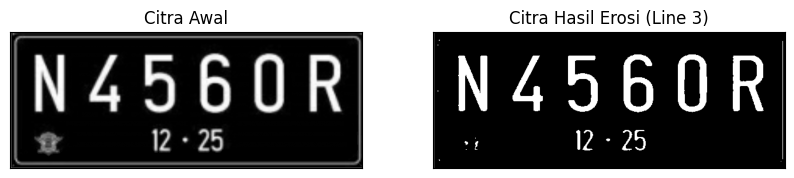

SE = Line Vertikal 5


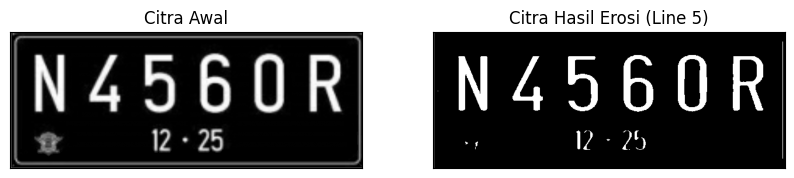

In [ ]:
img_e = cv2.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /plat_nomor.png', 0) # Pastikan ada j.png atau ganti plat_nomer
if img_e is None:
    img_e = cv2.imread('//content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /plat_nomor.png', 0) # fallback
if img_e is not None:
    ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

    print('SE = Line Vertikal 3')
    SE_line_3 = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 3))
    imgE_line_3 = cv2.erode(thresh1, SE_line_3, iterations=1)

    plt.figure(figsize=(10,5))
    plt.subplot(121), plt.imshow(img_e, cmap='gray'), plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(imgE_line_3, cmap='gray'), plt.title('Citra Hasil Erosi (Line 3)')
    plt.xticks([]), plt.yticks([])
    plt.show()

    print('SE = Line Vertikal 5')
    SE_line_5 = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 5))
    imgE_line_5 = cv2.erode(thresh1, SE_line_5, iterations=1)

    plt.figure(figsize=(10,5))
    plt.subplot(121), plt.imshow(img_e, cmap='gray'), plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(imgE_line_5, cmap='gray'), plt.title('Citra Hasil Erosi (Line 5)')
    plt.xticks([]), plt.yticks([])
    plt.show()


## 13. Top Hat Transform


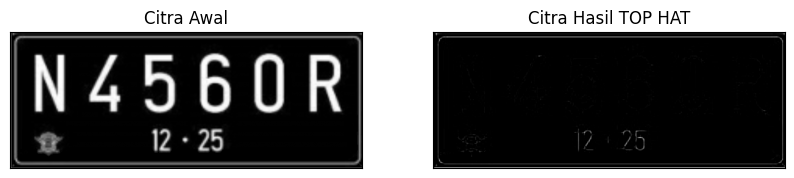

In [ ]:
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /plat_nomor.png', 0)
if img is not None:
    # Applying the Top-Hat operation
    tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

    plt.figure(figsize=(10,5))
    plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(tophat_img, cmap='gray'), plt.title('Citra Hasil TOP HAT')
    plt.xticks([]), plt.yticks([])
    plt.show()


## 14. Black Hat (Bottom Hat) Transform


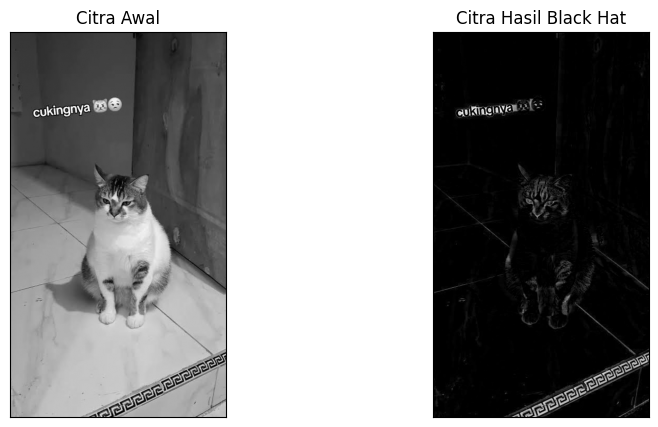

In [ ]:
img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /cuking.jpg', 0)
if img is None:
    img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /plat_nomor.png', 0) # fallback
if img is not None:
    Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
    blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

    plt.figure(figsize=(10,5))
    plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('Citra Awal')
    plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(blackhat, cmap='gray'), plt.title('Citra Hasil Black Hat')
    plt.xticks([]), plt.yticks([])
    plt.show()


## 15 & 16. Skeletonize dan Skeleton Inverse


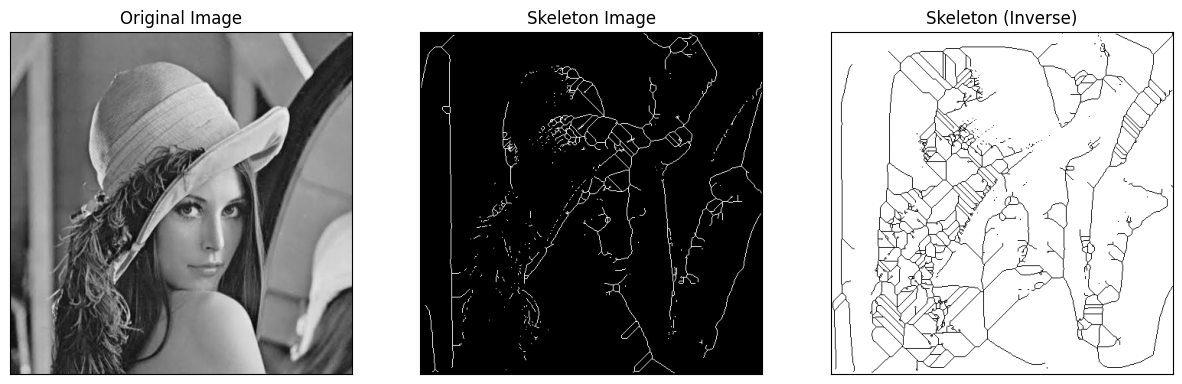

In [ ]:
# Menggunakan scikit-image
img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Lena.jpg', 0)
if img is None:
    img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /plat_nomor.png', 0) # fallback
if img is not None:
    binary = img > filters.threshold_triangle(img)

    # Karena True/False perlu dikonversi atau dipastikan formatnya
    binary_cp = binary.copy()

    # Skeletonize image
    skeleton = morphology.skeletonize(binary_cp)

    # Skeletonize inverse (bila objeknya bernilai False/0)
    binary_inv = img < filters.threshold_triangle(img)
    skeleton_inv = morphology.skeletonize(binary_inv)

    plt.figure(figsize=(15, 5))
    plt.subplot(131), plt.imshow(img, cmap='gray'), plt.title('Original Image')
    plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(skeleton, cmap='gray'), plt.title('Skeleton Image')
    plt.xticks([]), plt.yticks([])
    plt.subplot(133), plt.imshow(skeleton_inv, cmap='gray_r'), plt.title('Skeleton (Inverse)')
    plt.xticks([]), plt.yticks([])
    plt.show()


## 17. Thickening (Thinning pada Scikit-Image)


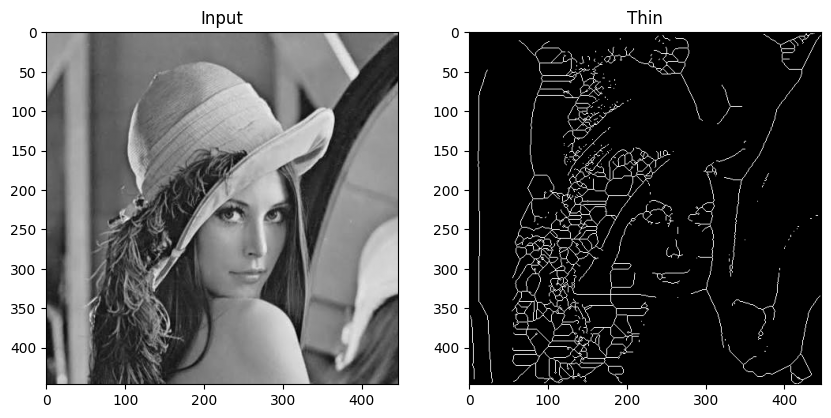

In [ ]:
img_path = '/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Lena.jpg'
image = cv2.imread(img_path, 0)
if image is None:
    image = cv2.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /plat_nomor.png', 0) # fallback

if image is not None:
    image_float = img_as_float(image)
    image_binary = image_float < 0.5

    out_thin = morphology.thin(image_binary)

    f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 5))
    ax0.imshow(image, cmap='gray')
    ax0.set_title('Input')
    ax1.imshow(out_thin, cmap='gray')
    ax1.set_title('Thin')
    plt.show()


## Tugas Praktikum: Morfologi Citra KTP
Implementasi morfologi pada dataset KTP agar tulisan KTP terbaca lebih jelas.


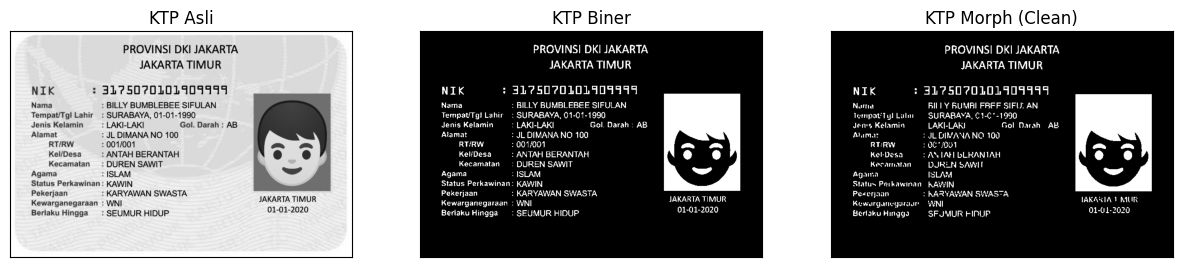

In [ ]:
# Kerangka Tugas Praktikum
img_ktp = cv2.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /ktp tumbal.jpeg', 0)
if img_ktp is not None:
    # 1. Binarization (Thresholding)
    ret, thresh_ktp = cv2.threshold(img_ktp, 127, 255, cv2.THRESH_BINARY_INV) # INV agar teks berwarna putih

    # 2. Morfologi untuk menghilangkan noise atau memperjelas teks (misal: Opening/Closing)
    # Gunakan kernel ukuran teks yang sesuai
    kernel_ktp = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
    ktp_morph = cv2.morphologyEx(thresh_ktp, cv2.MORPH_OPEN, kernel_ktp)

    # 3. Tampilkan hasil
    plt.figure(figsize=(15,5))
    plt.subplot(131), plt.imshow(img_ktp, cmap='gray'), plt.title('KTP Asli')
    plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(thresh_ktp, cmap='gray'), plt.title('KTP Biner')
    plt.xticks([]), plt.yticks([])
    plt.subplot(133), plt.imshow(ktp_morph, cmap='gray'), plt.title('KTP Morph (Clean)')
    plt.xticks([]), plt.yticks([])
    plt.show()
else:
    print("Silakan siapkan citra ktp.jpg di dalam folder /content/drive/MyDrive/PCVK/Images/")
